# Suberised vs. Unsuberised Bundle Sheath Comparison
This notebook compares the metabolic behavior of C4 models with and without a suberised layer in the Bundle Sheath cells. The suberised layer restricts gas diffusion (CO2 and O2), which is a key feature of C4 photosynthesis. We analyze the impact of this anatomical constraint on Rubisco flux, metabolite transport, and electron transport.

## 1. Setup and Imports
Import necessary libraries and load the metabolic model.

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import pandas as pd
import sys
from Auxiliary import *
from Flux import *
from Visualization import *
import numpy as np
import altair as alt
from cobra.io import read_sbml_model
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
pd.options.mode.chained_assignment = None  # default='warn'
import plotly
plotly.offline.init_notebook_mode(connected=True)

## 2. Data Preparation
Load and structure simulation results for both suberised and unsuberised scenarios across different photosynthetic modes (C3, Variable, C4-only).

### 2.1 Suberised Scenarios
Process data where the Bundle Sheath is suberised (gas diffusion restricted).

In [2]:
# Load the C4 metabolic model
c4_model = read_sbml_model("../Models/c4_model.xml")

Set parameter Username
Academic license - for non-commercial use only - expires 2027-01-20


In [3]:
# --- C3 Suberised ---
df_C3 = pd.read_csv("../Datasets/Scan_C3_Weighted_Suberised.csv")

In [4]:
structured_C3 = structure_data(df=df_C3, model=c4_model, filename="../Datasets/C3_Weighted_Structured_Suberised.csv")

In [5]:
structured_C3["Quantum Requirement"] = (structured_C3["Light Mesophyll"] + structured_C3["Light Bundle Sheath"]) / structured_C3["Carbon Uptake"]

In [6]:
selected_C3 = select_data(prepared_df=structured_C3, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS = 1, NH3 = 1000)

In [7]:
selected_C3

,Vc_Vo,PPFD,V_BS_M,Maximum Nitrogen Uptake,Maximum Carbon Uptake,Carbon Uptake,Nitrogen Uptake,Light Mesophyll,Light Bundle Sheath,PC_M,...,Glutamine_syn_m_M,Glutamine_syn_p_M,Glutamine_syn_c_B,Glutamine_syn_m_B,Glutamine_syn_p_B,Glycolate oxidase M,Phosphoglycolate phosphatase M,Glycolate oxidase B,Phosphoglycolate phosphatase B,Quantum Requirement
5,75.0,1000,0.4,1000.0,20.0,20.0,3.7,349.214286,9.171429,1.0,...,0.000000,7.928571,0.0,0.0,0.000000,10.9,10.9,0.0,0.0,17.919286
16,75.0,1000,0.5,1000.0,20.0,20.0,3.7,349.000000,9.466667,1.0,...,0.000000,7.933333,0.0,0.0,0.000000,11.7,11.7,0.0,0.0,17.923333
27,75.0,1000,0.6,1000.0,20.0,20.0,3.7,348.750000,9.712500,1.0,...,0.000000,7.937500,0.0,0.0,0.000000,12.5,12.5,0.0,0.0,17.923125
38,75.0,1000,0.7,1000.0,20.0,20.0,3.7,348.529412,9.923529,1.0,...,0.058824,7.882353,0.0,0.0,0.000000,13.3,13.3,0.0,0.0,17.922647
49,75.0,1000,0.8,1000.0,20.0,20.0,3.7,348.388889,10.133333,1.0,...,0.055556,7.888889,0.0,0.0,0.000000,14.1,14.1,0.0,0.0,17.926111
60,75.0,1000,0.9,1000.0,20.0,20.0,3.7,348.210526,10.278947,1.0,...,0.000000,7.947368,0.0,0.0,0.000000,14.8,14.8,0.0,0.0,17.924474
71,75.0,1000,1.0,1000.0,20.0,20.0,3.7,348.100000,10.450000,1.0,...,0.050000,7.850000,0.0,0.0,0.000000,15.6,15.6,0.0,0.0,17.927500
82,75.0,1000,1.1,1000.0,20.0,20.0,3.7,347.952381,10.580952,1.0,...,0.095238,7.857143,0.0,0.0,0.000000,16.4,16.4,0.0,0.0,17.926667
93,75.0,1000,1.2,1000.0,20.0,20.0,3.7,347.863636,10.690909,1.0,...,0.000000,7.954545,0.0,0.0,0.000000,17.2,17.2,0.0,0.0,17.927727
104,75.0,1000,1.3,1000.0,20.0,20.0,3.7,347.739130,10.852174,1.0,...,0.000000,7.956522,0.0,0.0,0.000000,18.0,18.0,0.0,0.0,17.929565


In [8]:
# --- Variable (Free Choice) Suberised ---
df_C4 = pd.read_csv("../Datasets/Scan_Variable_Weighted_Suberised.csv")

In [9]:
structured_C4 = structure_data(df=df_C4, model = c4_model, filename="../Datasets/Variable_Weighted_Structured_Suberised.csv")

structured_C4["Quantum Requirement"] = (structured_C4["Light Mesophyll"] + structured_C4["Light Bundle Sheath"]) / structured_C4["Carbon Uptake"]

In [10]:
selected_C4 = select_data(prepared_df=structured_C4, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS = 1, NH3 = 1000)

selected_C4

,Vc_Vo,PPFD,V_BS_M,Maximum Nitrogen Uptake,Maximum Carbon Uptake,Carbon Uptake,Nitrogen Uptake,Light Mesophyll,Light Bundle Sheath,PC_M,...,Glutamine_syn_m_M,Glutamine_syn_p_M,Glutamine_syn_c_B,Glutamine_syn_m_B,Glutamine_syn_p_B,Glycolate oxidase M,Phosphoglycolate phosphatase M,Glycolate oxidase B,Phosphoglycolate phosphatase B,Quantum Requirement
5,75.0,1000,0.4,1000.0,20.0,20.0,3.7,349.214286,9.171429,1.0,...,0.071429,7.857143,0.0,0.0,0.000000,10.9,10.9,0.0,0.0,17.919286
16,75.0,1000,0.5,1000.0,20.0,20.0,3.7,349.000000,9.466667,1.0,...,0.066667,7.866667,0.0,0.0,0.000000,11.7,11.7,0.0,0.0,17.923333
27,75.0,1000,0.6,1000.0,20.0,20.0,3.7,348.750000,9.712500,1.0,...,0.062500,7.875000,0.0,0.0,0.000000,12.5,12.5,0.0,0.0,17.923125
38,75.0,1000,0.7,1000.0,20.0,20.0,3.7,345.117647,11.076471,1.0,...,0.000000,7.764706,0.0,0.0,0.082353,13.0,13.0,0.0,0.0,17.809706
49,75.0,1000,0.8,1000.0,20.0,20.0,3.7,344.000000,11.866667,1.0,...,0.000000,7.722222,0.0,0.0,0.088889,13.7,13.7,0.0,0.0,17.793333
60,75.0,1000,0.9,1000.0,20.0,20.0,3.7,341.736842,13.452632,1.0,...,0.000000,7.631579,0.0,0.0,0.142105,14.3,14.3,0.0,0.0,17.759474
71,75.0,1000,1.0,1000.0,20.0,20.0,3.7,339.150000,15.050000,1.0,...,0.000000,7.500000,0.0,0.0,0.200000,14.8,14.8,0.0,0.0,17.710000
82,75.0,1000,1.1,1000.0,20.0,20.0,3.7,337.380952,15.714286,1.0,...,0.000000,7.333333,0.0,0.0,0.366667,15.3,15.3,0.0,0.0,17.654762
93,75.0,1000,1.2,1000.0,20.0,20.0,3.7,336.409091,15.872727,1.0,...,0.000000,7.272727,0.0,0.0,0.436364,16.0,16.0,0.0,0.0,17.614091
104,75.0,1000,1.3,1000.0,20.0,20.0,3.7,334.434783,16.560870,1.0,...,0.000000,7.086957,0.0,0.0,0.565217,16.6,16.6,0.0,0.0,17.549783


In [11]:
# --- C4-Only Suberised ---
df_C4_only = pd.read_csv("../Datasets/Scan_C4_Weighted_Suberised.csv") 

structured_C4_only = structure_data(df=df_C4_only, model = c4_model, filename="../Datasets/C4_Weighted_Structured_Suberised.csv")

structured_C4_only["Quantum Requirement"] = (structured_C4_only["Light Mesophyll"] + structured_C4_only["Light Bundle Sheath"]) / structured_C4_only["Carbon Uptake"]

In [12]:
selected_C4_only = select_data(prepared_df=structured_C4_only, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS = 1, NH3 = 1000)

selected_C4_only

,Vc_Vo,PPFD,V_BS_M,Maximum Nitrogen Uptake,Maximum Carbon Uptake,Carbon Uptake,Nitrogen Uptake,Light Mesophyll,Light Bundle Sheath,PC_M,...,Glutamine_syn_m_M,Glutamine_syn_p_M,Glutamine_syn_c_B,Glutamine_syn_m_B,Glutamine_syn_p_B,Glycolate oxidase M,Phosphoglycolate phosphatase M,Glycolate oxidase B,Phosphoglycolate phosphatase B,Quantum Requirement
5,75.0,1000,0.4,1000.0,20.0,20.0,3.7,234.857143,126.428571,1.0,...,0.071429,4.857143,0.0,0.000000,4.314286,0.0,0.0,0.0,0.0,18.064286
16,75.0,1000,0.5,1000.0,20.0,20.0,3.7,229.000000,100.800000,1.0,...,0.000000,4.266667,0.0,0.000000,1.633333,0.0,0.0,0.0,0.0,16.490000
27,75.0,1000,0.6,1000.0,20.0,20.0,3.7,228.875000,95.775000,1.0,...,0.000000,3.750000,0.0,0.000000,1.125000,0.0,0.0,0.0,0.0,16.232500
38,75.0,1000,0.7,1000.0,20.0,20.0,3.7,228.705882,93.923529,1.0,...,0.000000,3.764706,0.0,0.000000,0.411765,0.0,0.0,0.0,0.0,16.131471
49,75.0,1000,0.8,1000.0,20.0,20.0,3.7,228.611111,93.822222,1.0,...,0.000000,3.777778,0.0,0.000000,0.266667,0.0,0.0,0.0,0.0,16.121667
60,75.0,1000,0.9,1000.0,20.0,20.0,3.7,228.473684,95.352632,1.0,...,0.000000,3.789474,0.0,0.000000,0.284211,0.0,0.0,0.0,0.0,16.191316
71,75.0,1000,1.0,1000.0,20.0,20.0,3.7,228.700000,90.300000,1.0,...,0.000000,3.650000,0.0,0.000000,0.350000,0.0,0.0,0.0,0.0,15.950000
82,75.0,1000,1.1,1000.0,20.0,20.0,3.7,231.714286,84.019048,1.0,...,0.000000,3.666667,0.0,0.366667,0.000000,0.0,0.0,0.0,0.0,15.786667
93,75.0,1000,1.2,1000.0,20.0,20.0,3.7,234.227273,77.563636,1.0,...,0.000000,3.772727,0.0,0.272727,0.000000,0.0,0.0,0.0,0.0,15.589545
104,75.0,1000,1.3,1000.0,20.0,20.0,3.7,235.304348,72.291304,1.0,...,0.000000,3.782609,0.0,0.282609,0.000000,0.0,0.0,0.0,0.0,15.379783


### 2.2 Unsuberised Scenarios
Process data where the Bundle Sheath is unsuberised (gas diffusion allowed).

In [13]:
# --- C3 Unsuberised ---
df_C3_unsuberised = pd.read_csv("../Datasets/Scan_C3_Weighted.csv")
structured_C3_unsuberised = structure_data(df=df_C3_unsuberised, model=c4_model, filename="../Datasets/C3_Weighted_Structured.csv")
selected_C3_unsuberised = select_data(prepared_df=structured_C3_unsuberised, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS = 1, NH3 = 1000)

In [14]:
# --- Variable (Free Choice) Unsuberised ---
df_C4_unsuberised = pd.read_csv("../Datasets/Scan_Variable_Weighted.csv")
structured_C4_unsuberised = structure_data(df=df_C4_unsuberised, model=c4_model, filename="../Datasets/Variable_Weighted_Structured.csv")
selected_C4_unsuberised = select_data(prepared_df=structured_C4_unsuberised, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS = 1, NH3 = 1000)

In [15]:
# --- C4-Only Unsuberised ---
df_C4_only_unsuberised = pd.read_csv("../Datasets/Scan_C4_Weighted.csv")
structured_C4_only_unsuberised = structure_data(df=df_C4_only_unsuberised, model=c4_model, filename="../Datasets/C4_Weighted_Structured.csv")
selected_C4_only_unsuberised = select_data(prepared_df=structured_C4_only_unsuberised, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS = 1, NH3 = 1000)

## 3. Rubisco Flux and Decarboxylation Analysis
Compare the flux through Rubisco and decarboxylation enzymes across different $V_{BS/M}$ ratios for both scenarios.

### 3.1 Suberised Scenario

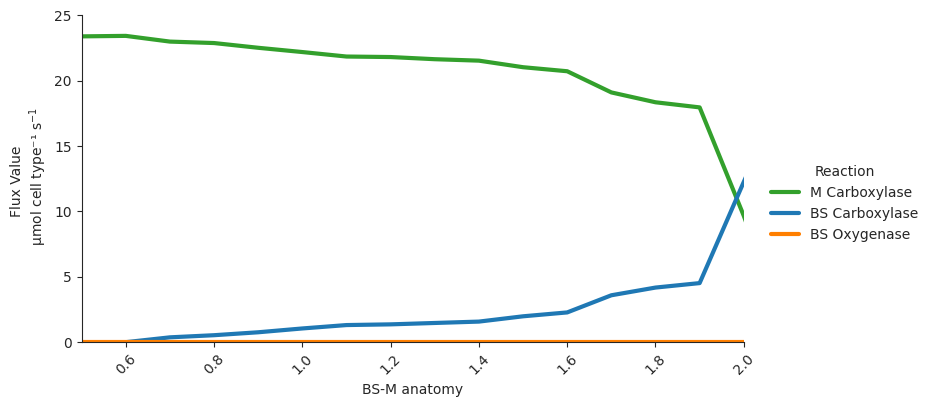

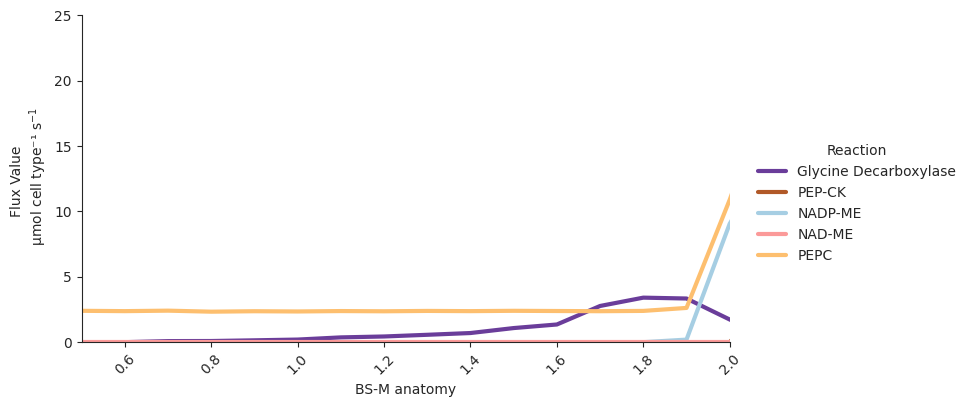

In [16]:
# Plot reaction fluxes vs Volume Ratio for Suberised case
g1, g2 = reaction_lineplot_VRatio_split(data=structured_C4, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3 = 1000)
#g1.savefig("suber2_2_A.svg", format="svg", dpi=300)
#g2.savefig("suber3_2_A.svg", format="svg", dpi=300)

### 3.2 Unsuberised Scenario

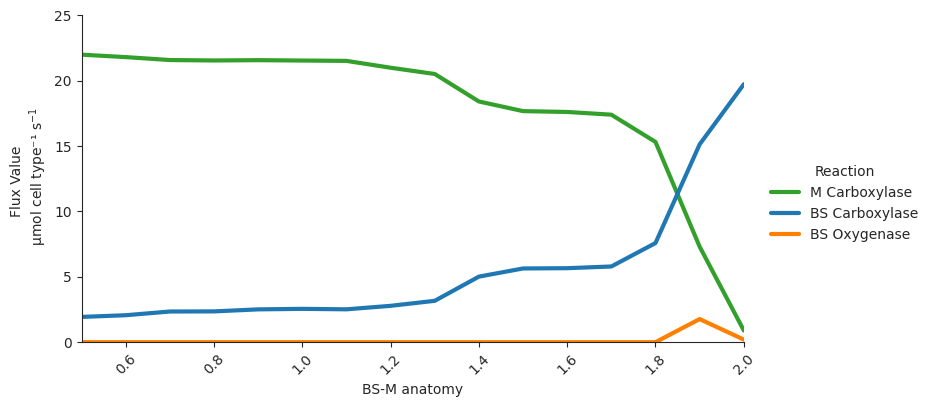

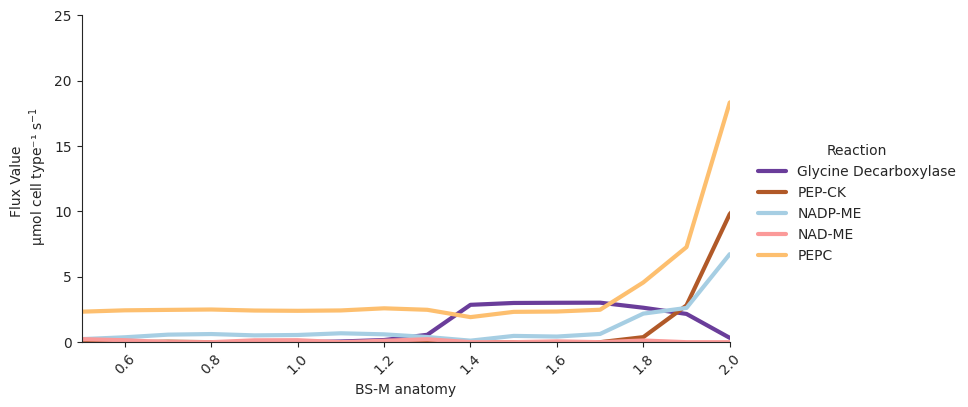

In [17]:
# Plot reaction fluxes vs Volume Ratio for Unsuberised case
g1, g2 = reaction_lineplot_VRatio_split(data=structured_C4_unsuberised, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3 = 1000)
#g1.savefig("suber2_1_A.svg", format="svg", dpi=300)
#g2.savefig("suber3_1_A.svg", format="svg", dpi=300)

## 4. Metabolite Transport Comparison
Visualize the differences in metabolite exchange between Mesophyll and Bundle Sheath cells using heatmaps.

In [18]:
# Filter unsuberised data for specific photorespiratory conditions
df_C4_unsuberised = pd.read_csv("../Datasets/Scan_Variable_Weighted.csv")
structured_C4_unsuberised = structure_data(df=df_C4_unsuberised, model=c4_model, filename="../Datasets/Variable_Weighted_Structured.csv")
structured_C4_unsuberised = structured_C4_unsuberised[structured_C4_unsuberised.Vc_Vo < 85].reset_index()

In [19]:
# Structure transporter data for both scenarios
transporters_structured_suberised = structure_data_transporters(df = df_C4, filename = "../Datasets/Variable_Weighted_Transporters_suberised.csv")
selected_transporters_suberised = select_data(prepared_df=transporters_structured_suberised, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3=1000)
selected_transporters_suberised = selected_transporters_suberised[selected_transporters_suberised['V_BS_M'] >= 0.49].copy()

transporters_structured = structure_data_transporters(df = df_C4_unsuberised, filename = "../Datasets/Variable_Weighted_Transporters.csv")
selected_transporters = select_data(prepared_df=transporters_structured, PPFD=1000, Vc_Vo=75, CO2=20, PC_BS=1, NH3=1000)
selected_transporters = selected_transporters[selected_transporters['V_BS_M'] >= 0.49].copy()

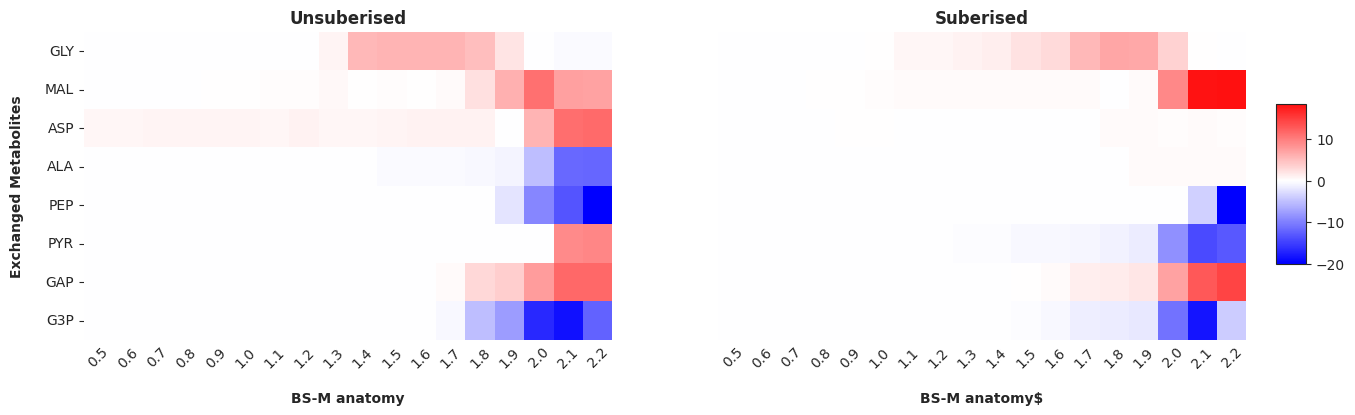

In [20]:
# Prepare data for heatmaps
plot_transporters = selected_transporters[["V_BS_M", "GLY", "GAP", "G3P", "PYR", "PEP", "ALA", "ASP", "MAL"]]
plot_transporters_suberised = selected_transporters_suberised[["V_BS_M", "GLY", "GAP", "G3P", "PYR", "PEP", "ALA", "ASP", "MAL"]]

df_suberised = pd.DataFrame(plot_transporters_suberised).set_index("V_BS_M").T
df_unsuberised = pd.DataFrame(plot_transporters).set_index("V_BS_M").T

desired_order = ["G3P", "GAP", "PYR", "PEP", "ALA", "ASP", "MAL", "GLY"] 
desired_order = desired_order[::-1] 

df_suberised = df_suberised.loc[desired_order]
df_unsuberised = df_unsuberised.loc[desired_order]

cmap = LinearSegmentedColormap.from_list("custom", ["blue", "white", "red"], N=256)

vmin = min(df_suberised.min().min(), df_unsuberised.min().min())
vmax = max(df_suberised.max().max(), df_unsuberised.max().max())

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharex=True, sharey=True, gridspec_kw={'width_ratios': [1, 1]})


sns.heatmap(
    df_unsuberised,
    cmap=cmap,
    center=0,
    cbar=False,  
    vmin=vmin,
    vmax=vmax,
    annot=False,
    fmt=".2f",
    ax=axes[0],
)
axes[0].set_title("Unsuberised", fontweight="bold")
axes[0].set_xlabel("BS-M anatomy", fontweight="bold", labelpad=15)
axes[0].set_ylabel("Exchanged Metabolites", fontweight="bold", labelpad=15)
axes[0].set_yticklabels(axes[0].get_yticklabels(),rotation=0, fontsize=10)

sns.heatmap(
    df_suberised,
    cmap=cmap,
    center=0,
    cbar=False,
    vmin=vmin,
    vmax=vmax,
    annot=False,
    fmt=".2f",
    ax=axes[1],
)
axes[1].set_title("Suberised", fontweight="bold")
axes[1].set_xlabel("BS-M anatomy$", fontweight="bold", labelpad=15)
axes[1].set_ylabel("Metabolites", fontweight="bold", labelpad=15)
axes[1].set_ylabel("")  
axes[1].tick_params(axis='y', length=0)

cbar_ax = fig.add_axes([0.92, 0.3, 0.02, 0.4])  
sns.heatmap(
    df_suberised,  
    cmap=cmap,
    cbar=False,
    cbar_kws={"label": "Flux value"},
    vmin=vmin,
    vmax=vmax,
    ax=None,
    xticklabels=True,
    yticklabels=False
)
cbar_ax.set_xlabel("")
cbar_ax.set_ylabel("asadasds", loc="top")
cbar_ax.invert_yaxis()

for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, fontsize=10)
    ax.xaxis.set_label_position('bottom')
    ax.xaxis.set_ticks_position('bottom')
    ax.tick_params(axis='x', length=0)



plt.colorbar(ax.get_children()[0], cax=cbar_ax)

# Adjust layout
#plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for the color bar
#plt.savefig("transporters_comparison.svg", format="svg", dpi=300)
plt.show()

## 5. Electron Transport Analysis
Analyze the flux through Linear and Cyclic Electron Transport (LET/CET) and Photosystems I and II in the Bundle Sheath.

In [21]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def plot_dual_v_ratio(data_unsub, data_sub, PPFD, Vc_Vo, CO2, PC_BS, NH3):
    """
    Processes two datasets (Unsuberised and Suberised) and generates 
    side-by-side subplots with a shared y-axis and a single legend.
    """
    sns.set_style("ticks")
    line_styles = {"PSI": "", "PSII": "", "Cyclic Electron Transport": (2, 2), "Linear Electron Transport": (2, 2)}
    custom_palette = {"PSI": "#bf5846", "PSII": "#30766a", "Cyclic Electron Transport": "#7eb2dd", "Linear Electron Transport": "#731727"}
    reaction_map = {"BS PSI": "PSI", "BS PSII": "PSII", "BS CET": "Cyclic Electron Transport", "BS LET": "Linear Electron Transport"}

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
    axes = [ax1, ax2]
    datasets = [data_unsub, data_sub]
    titles = ["Unsuberised Case", "Suberised Case"]

    for i, data in enumerate(datasets):
        selected = select_data(prepared_df=data, PPFD=PPFD, Vc_Vo=Vc_Vo, CO2=CO2, PC_BS=PC_BS, NH3=NH3)
        selected = selected[selected['V_BS_M'] >= 0.49].copy()

        melted = pd.melt(
            selected, 
            id_vars=['V_BS_M'], 
            value_vars=['BS PSI', 'BS PSII', 'BS CET', 'BS LET'],
            var_name='Reactions', 
            value_name='Rubisco_Value'
        )
        melted["Reactions"] = melted["Reactions"].map(reaction_map)

        sns.lineplot(
            data=melted, x="V_BS_M", y="Rubisco_Value", 
            hue="Reactions", style="Reactions", 
            dashes=line_styles, palette=custom_palette, 
            linewidth=3, alpha=0.7, ax=axes[i], legend=(i == 0) 
        )

        axes[i].set_title(titles[i], fontsize=18, fontweight='bold')
        axes[i].set_xlabel("V$_{BS/M}$")
        axes[i].set_xlim(0.5, 2)
        axes[i].set_ylim(0, 100)
        axes[i].set_xticks(np.arange(0.6, 2.1, 0.2))
        axes[i].tick_params(axis='x', labelrotation=45)
        
        if i == 0:
            axes[i].set_ylabel("Flux Value \n (µmol m$^{-2}$ s$^{-1}$)", fontsize=12, fontweight='bold')
        else:
            axes[i].set_ylabel("") 

    handles, labels = ax1.get_legend_handles_labels()
    ax1.get_legend().remove() 
    
    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(0.92, 0.5), title="Reactions")
    
    plt.tight_layout()
    plt.subplots_adjust(right=0.88) 
    return fig

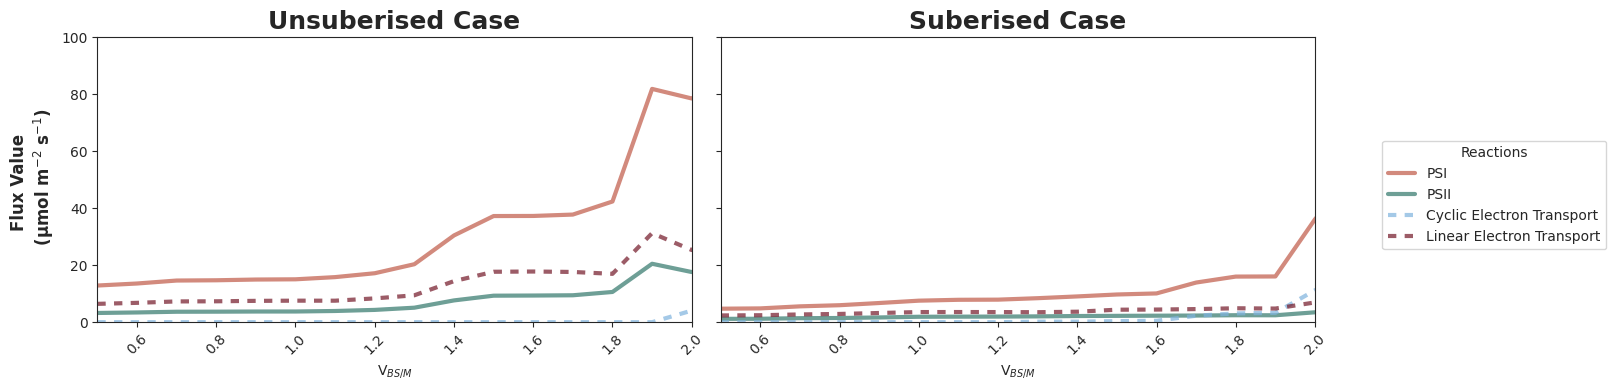

In [22]:
fig = plot_dual_v_ratio(
    data_unsub=structured_C4_unsuberised, 
    data_sub=structured_C4, 
    PPFD=1000, 
    Vc_Vo=75, 
    CO2=20, 
    PC_BS=1, 
    NH3=1000
)
#plt.savefig("suber1_A.svg", format="svg", dpi=300)
plt.show()

In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def plot_v_ratio_stacked(data_unsub, data_sub, PPFD, Vc_Vo, CO2, PC_BS, NH3):
    """
    Generates stacked bar plots with a single unified legend on the right,
    separated by category headers: Photosystems and Electron Transport.
    """
    # Select and Filter Data for V_BS_M
    value_V_BS_M = 2.0
    selected_unsub = select_data(prepared_df=data_unsub, PPFD=PPFD, Vc_Vo=Vc_Vo, CO2=CO2, PC_BS=PC_BS, NH3=NH3)
    selected_sub = select_data(prepared_df=data_sub, PPFD=PPFD, Vc_Vo=Vc_Vo, CO2=CO2, PC_BS=PC_BS, NH3=NH3)
    
    row_unsub = selected_unsub[np.isclose(selected_unsub['V_BS_M'], value_V_BS_M)].copy()
    row_sub = selected_sub[np.isclose(selected_sub['V_BS_M'], value_V_BS_M)].copy()
    
    row_sub['Case'] = 'suberised'
    row_unsub['Case'] = 'non-suberised'
    combined = pd.concat([row_unsub, row_sub])

    print(f"--- Analysis for Volume Ratio: {value_V_BS_M} ---")

    # Unsuberised
    psi_unsub = row_unsub['BS PSI'].values[0]
    psii_unsub = row_unsub['BS PSII'].values[0]
    let_unsub = row_unsub['BS LET'].values[0]
    cet_unsub = row_unsub['BS CET'].values[0]

    print(f"\n[Unsuberised Scenario]")
    print(f"PSI Flux: {psi_unsub:.2f}")
    print(f"PSII Flux: {psii_unsub:.2f}")
    print(f"PSI:PSII Ratio: {(psi_unsub / psii_unsub):.2f}")
    print(f"Linear Flux (LET): {let_unsub:.2f}")
    print(f"Cyclic Flux (CET): {cet_unsub:.2f}")
    print(f"Linear:Cyclic Ratio: {(let_unsub / cet_unsub):.2f}")

    # Suberised 
    psi_sub = row_sub['BS PSI'].values[0]
    psii_sub = row_sub['BS PSII'].values[0]
    let_sub = row_sub['BS LET'].values[0]
    cet_sub = row_sub['BS CET'].values[0]

    # Percentage difference
    psi_diff_pct = (psi_sub / psi_unsub) * 100
    psii_diff_pct = (psii_sub / psii_unsub) * 100

    print(f"\n[Suberised Scenario]")
    print(f"New Linear:Cyclic Ratio: {(let_sub / cet_sub):.2f}")
    print(f"\n[Comparison: Effect of Suberisation]")
    print(f"PSI Flux declining: {psi_diff_pct:.2f}%")
    print(f"PSII Flux declining: {psii_diff_pct:.2f}%")
    print("-" * 40)
    
    photo_map = {"BS PSII": "Photosystem II", "BS PSI": "Photosystem I"}
    et_map = {"BS LET": "Linear", "BS CET": "Cyclic"}
    
    custom_palette = {
        "Photosystem I": "#659DF2", "Photosystem II": "#FFDC4A",
        "Cyclic": "#91a336", "Linear": "#ce5d5d"
    }

    # Plot
    sns.set_style("ticks")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 6))

    # Photosystems ---
    df_photo = combined.set_index('Case')[["BS PSII", "BS PSI"]].rename(columns=photo_map)
    df_photo.plot(kind='bar', stacked=True, ax=ax1, width=0.5, legend=False,
                  color=[custom_palette[c] for c in df_photo.columns], edgecolor='white')
    
    ax1.set_ylim(0, df_photo.sum(axis=1).max() * 1.1)
    ax1.set_ylabel("Flux (µmol cell type$^{-1}$ s$^{-1}$)", fontsize=16, fontweight='bold')

    # --- Electron Transport ---
    df_et = combined.set_index('Case')[["BS CET", "BS LET"]].rename(columns=et_map)
    df_et.plot(kind='bar', stacked=True, ax=ax2, width=0.5, legend=False,
               color=[custom_palette[c] for c in df_et.columns], edgecolor='white')
    
    ax2.set_ylim(0, df_et.sum(axis=1).max() * 1.1)
    ax2.set_ylabel("", fontsize=10, fontweight='bold')

    for ax in [ax1, ax2]:
        ax.set_xlabel("")
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor', fontsize=14)
        ax.tick_params(axis='both', which='major', labelsize=14)
        sns.despine(ax=ax)

    legend_elements = [
        Patch(color='none', label='Bundle Sheath\nPhotosystem'), 
        Patch(facecolor=custom_palette["Photosystem I"], edgecolor='white', label='Photosystem I'),
        Patch(facecolor=custom_palette["Photosystem II"], edgecolor='white', label='Photosystem II'),
        Patch(color='none', label=''), 
        Patch(color='none', label='Bundle Sheath\nElectron Transport'), 
        Patch(facecolor=custom_palette["Linear"], edgecolor='white', label='Linear'),
        Patch(facecolor=custom_palette["Cyclic"], edgecolor='white', label='Cyclic')
    ]

    leg = fig.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(0.9, 0.5), 
                     frameon=False, fontsize=16, handlelength=1.0)

    for text in leg.get_texts():
        if "Bundle Sheath" in text.get_text():
            text.set_fontweight('bold')
    

    plt.tight_layout()
    plt.subplots_adjust(right=0.75) 
    plt.savefig("../Images/bar_PSI_v2.svg", format="svg", bbox_inches="tight")
    

--- Analysis for Volume Ratio: 2.0 ---

[Unsuberised Scenario]
PSI Flux: 78.53
PSII Flux: 17.60
PSI:PSII Ratio: 4.46
Linear Flux (LET): 25.33
Cyclic Flux (CET): 4.07
Linear:Cyclic Ratio: 6.23

[Suberised Scenario]
New Linear:Cyclic Ratio: 0.62

[Comparison: Effect of Suberisation]
PSI Flux declining: 46.01%
PSII Flux declining: 19.70%
----------------------------------------


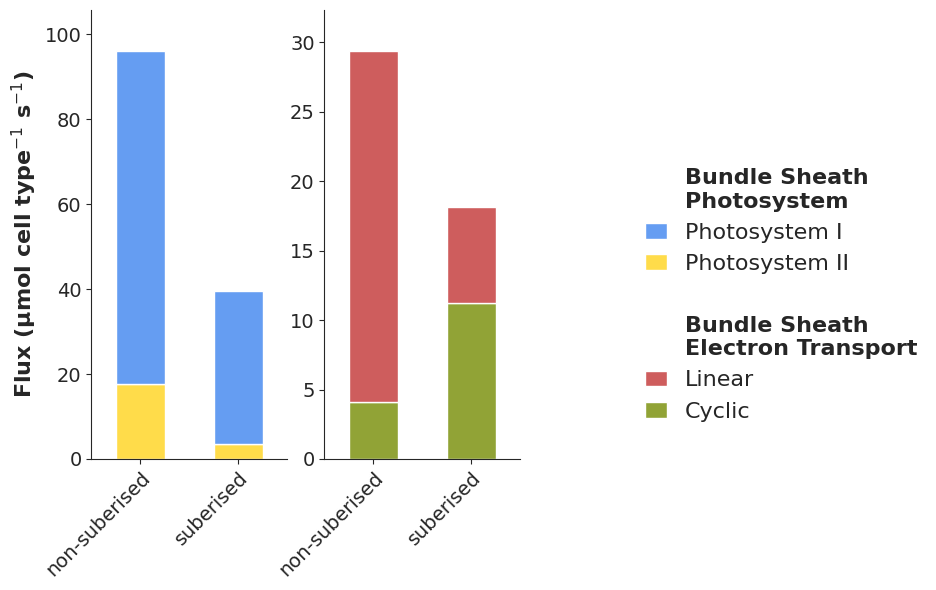

In [24]:
plot_v_ratio_stacked(
    data_unsub=structured_C4_unsuberised, 
    data_sub=structured_C4, 
    PPFD=1000, 
    Vc_Vo=75, 
    CO2=20, 
    PC_BS=1, 
    NH3=1000
)

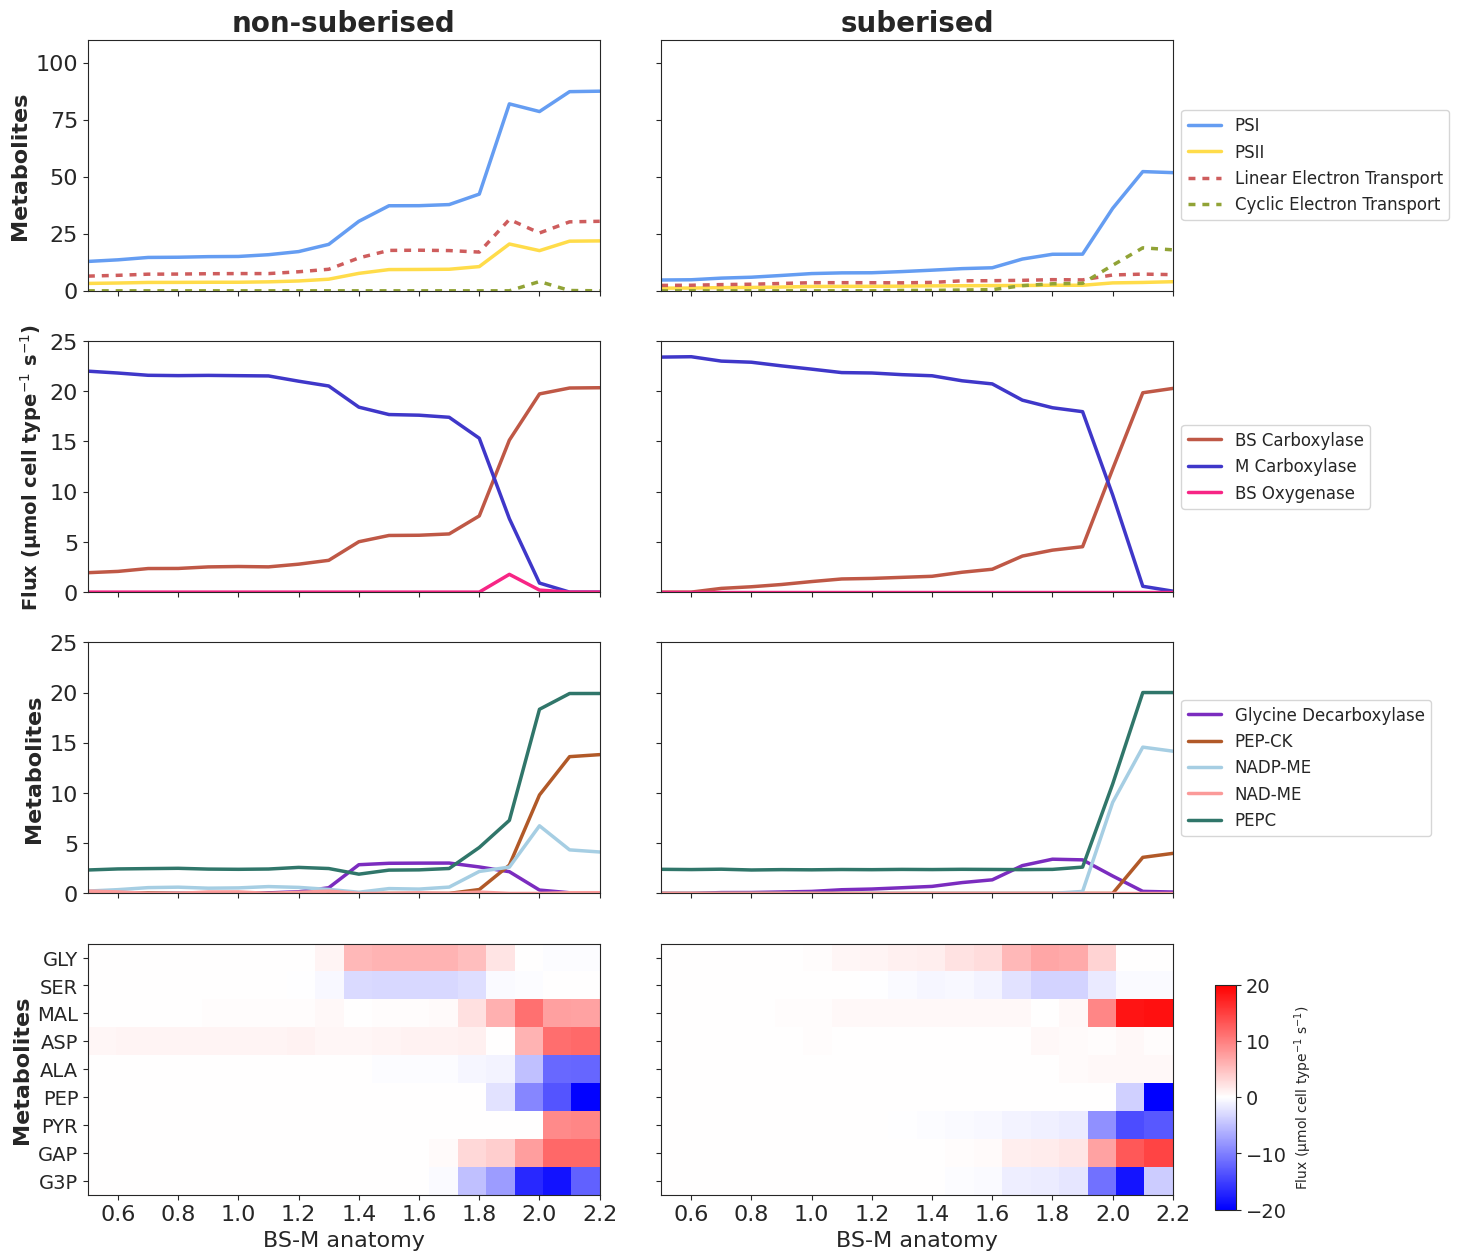

In [25]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

def plot_comprehensive_grid(data_unsub, data_sub, selected_trans_unsub, selected_trans_sub, PPFD, Vc_Vo, CO2, PC_BS, NH3):
    sns.set_style("ticks")
    
    fig, axes = plt.subplots(4, 2, figsize=(14, 15), gridspec_kw={'height_ratios': [1, 1, 1, 1]})
    
    datasets = [data_unsub, data_sub]
    titles = ["non-suberised", "suberised"]
    X_MIN, X_MAX = 0.5, 2.2 
    
    line_styles = {"PSI": "", "PSII": "", "Cyclic Electron Transport": (2, 2), "Linear Electron Transport": (2, 2)}
    energy_palette = {"PSI": "#659DF2", "PSII": "#FFDC4A", "Cyclic Electron Transport": "#91a336", "Linear Electron Transport": "#ce5d5d"}
    energy_map = {"BS PSI": "PSI", "BS PSII": "PSII", "BS CET": "Cyclic Electron Transport", "BS LET": "Linear Electron Transport"}
    rub_palette = {'BS Carboxylase': '#bf5846', 'M Carboxylase': '#3f37c9', 'BS Oxygenase': '#f72585'}
    dec_palette = {'Glycine Decarboxylase': '#7b2cbf', 'PEP-CK': '#b15928', 'NADP-ME': '#a6cee3', 'NAD-ME': '#fb9a99', 'PEPC': '#30766a'}

    heatmap_order = ["GLY", "SER", "MAL", "ASP", "ALA", "PEP", "PYR", "GAP", "G3P"]

    for i, data in enumerate(datasets):
        selected = select_data(prepared_df=data, PPFD=PPFD, Vc_Vo=Vc_Vo, CO2=CO2, PC_BS=PC_BS, NH3=NH3).copy()
        
        # --- Energy Flux ---
        energy_data = selected[selected['V_BS_M'] >= 0.49].copy()
        melt_energy = pd.melt(energy_data, id_vars=['V_BS_M'], value_vars=list(energy_map.keys()), var_name='Reactions', value_name='Val')
        melt_energy["Reactions"] = melt_energy["Reactions"].map(energy_map)
        
        energy_order = ["PSI", "PSII", "Linear Electron Transport", "Cyclic Electron Transport"]
        melt_energy["Reactions"] = pd.Categorical(melt_energy["Reactions"], categories=energy_order, ordered=True)
        
        sns.lineplot(
            data=melt_energy, 
            x="V_BS_M", 
            y="Val", 
            hue="Reactions", 
            style="Reactions", 
            hue_order=energy_order,        
            style_order=energy_order,     
            dashes=line_styles, 
            palette=energy_palette, 
            linewidth=2.5, 
            ax=axes[0, i], 
            legend=(i==1)
        )
        axes[0, i].set_title(f"{titles[i]}", fontsize=20, fontweight='bold')
        axes[0, i].set_ylim(0, 110)

        v_ratio = selected['V_BS_M']
        v_m = 1 / (1 + v_ratio)
        v_bs = v_ratio / (1 + v_ratio)
        
        selected['BS_Carb'] = (selected['BS_Rubisco'] + selected.get('BS_Rubisco_C4', 0)) * v_bs
        selected['M_Carb'] = selected['M_Rubisco'] * v_m
        selected['BS_Oxy'] = selected['BS Oxygenase'] * v_bs
        
        # ---  Rubisco ---
        df_rub = pd.melt(selected, id_vars=['V_BS_M'], value_vars=['BS_Carb', 'M_Carb', 'BS_Oxy'], var_name='Reaction', value_name='Flux')
        df_rub['Reaction'] = df_rub['Reaction'].map({'BS_Carb': 'BS Carboxylase', 'M_Carb': 'M Carboxylase', 'BS_Oxy': 'BS Oxygenase'})
        sns.lineplot(data=df_rub, x="V_BS_M", y="Flux", hue="Reaction", palette=rub_palette, linewidth=2.5, ax=axes[1, i], legend=(i==1))
        axes[1, i].set_ylim(0, 25)

        # --- Decarboxylation ---
        for col in ['Glycine Decarboxylase', 'PEP-CK', 'NADP-ME', 'NAD-ME']:
            if col in selected.columns:
                selected[col] = selected[col] * v_bs
        selected['PEPC_scaled'] = selected['PEPC'] * v_m
        
        df_dec = pd.melt(selected, id_vars=['V_BS_M'], 
                         value_vars=['Glycine Decarboxylase', 'PEP-CK', 'NADP-ME', 'NAD-ME', 'PEPC_scaled'], 
                         var_name='Reaction', value_name='Flux')
        df_dec['Reaction'] = df_dec['Reaction'].replace({'PEPC_scaled': 'PEPC'})
        sns.lineplot(data=df_dec, x="V_BS_M", y="Flux", hue="Reaction", palette=dec_palette, linewidth=2.5, ax=axes[2, i], legend=(i==1))
        axes[2, i].set_ylim(0, 25)

    # --- Heatmaps (Transporters) ---
    cmap = LinearSegmentedColormap.from_list("custom", ["blue", "white", "red"], N=256)
    df_h_unsub = selected_trans_unsub.set_index("V_BS_M")[heatmap_order].T
    df_h_sub = selected_trans_sub.set_index("V_BS_M")[heatmap_order].T
    
    all_vals = pd.concat([selected_trans_unsub[heatmap_order], selected_trans_sub[heatmap_order]])
    limit = max(abs(all_vals.min().min()), abs(all_vals.max().max()))

    for i, df_h in enumerate([df_h_unsub, df_h_sub]):
        im = axes[3, i].imshow(df_h.values, cmap=cmap, aspect='auto', 
                               vmin=-limit, vmax=limit, origin='upper',
                               extent=[X_MIN, X_MAX, len(heatmap_order)-0.5, -0.5])
        
        axes[3, i].set_xticks([0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2])
        axes[3, i].set_yticks(range(len(heatmap_order)))
        
        if i == 0:
            axes[3, i].set_yticklabels(heatmap_order, fontsize=14)
        else:
            axes[3, i].set_yticklabels([])

    for r in range(4):
        for c in range(2):
            axes[r, c].tick_params(axis='both', which='major', labelsize=16)
            axes[r, c].set_xlim(X_MIN, X_MAX)
            
            if r < 3:
                axes[r, c].set_xticks([0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2])
                axes[r, c].set_xlabel("")
                axes[r, c].tick_params(labelbottom=False)
            
            if c == 1:
                axes[r, c].set_ylabel("")
                axes[r, c].tick_params(labelleft=False) 
                if r < 3:
                    axes[r, c].legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=12)

            if c == 0:
                if r == 1:
                    axes[r, c].set_ylabel("Flux (µmol cell type$^{-1}$ s$^{-1}$)", fontsize=14, fontweight='bold')
                else:
                    axes[r, 0].set_ylabel("Metabolites", fontsize=16, fontweight='bold')

    axes[3, 0].set_yticklabels(heatmap_order, fontsize=14)
    axes[3, 0].set_xlabel("BS-M anatomy", fontsize=16)
    axes[3, 1].set_xlabel("BS-M anatomy", fontsize=16)
    
    cbar_ax = fig.add_axes([0.93, 0.1, 0.015, 0.15])
    cbar = fig.colorbar(im, cax=cbar_ax, label="Flux (µmol cell type$^{-1}$ s$^{-1}$)")
    cbar.ax.tick_params(labelsize=14) # Colorbar tick font

    plt.subplots_adjust(wspace=0.12, hspace=0.2)
    return fig

fig = plot_comprehensive_grid(
    structured_C4_unsuberised, structured_C4, 
    selected_transporters, selected_transporters_suberised,
    1000, 75, 20, 1, 1000
)
plt.savefig("../Images/suberised_grid_ALR.svg", format="svg", bbox_inches="tight")
plt.show()

In [26]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

def sub_vs_unsub_comparison_subplots(df_unsub, df_sub, PPFD, Vc_Vo, CO2, PC_BS, NH3, volume_ratio):
    plt.rcParams.update({
        'font.size': 16,
        'axes.titlesize': 22,
        'axes.labelsize': 16,
        'xtick.labelsize': 16,
        'ytick.labelsize': 16,
        'legend.fontsize': 16})

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 10), sharex=False)
    volume_ratios = [volume_ratio]
    
    color_map = {'C3': '#64a4ceff', 'C3_C4_Type_I': '#e6954cfb', 'C4': '#69c569fe', 'Unidentified': '#884405fb'}
    hatch_params = {'edgecolor': 'black', 'linewidth': 0}

    def get_data():
        s_unsub = select_data(prepared_df=df_unsub, PPFD=PPFD, Vc_Vo=Vc_Vo, CO2=CO2, PC_BS=PC_BS, NH3=NH3)
        s_sub = select_data(prepared_df=df_sub, PPFD=PPFD, Vc_Vo=Vc_Vo, CO2=CO2, PC_BS=PC_BS, NH3=NH3)
        
        s_unsub = s_unsub[s_unsub.V_BS_M.isin(volume_ratios)].copy()
        s_sub = s_sub[s_sub.V_BS_M.isin(volume_ratios)].copy()
        
        s_unsub['Anatomy'] = "non-suberised"
        s_sub['Anatomy'] = "suberised"
        
        return pd.concat([s_unsub, s_sub])

    df_combined = get_data()

    plot_configs = [
        (ax1, "Sum of Fluxes", "SoF transport", "SoF M", "SoF BS", True),
        (ax3, "Light Uptake", "Light Mesophyll", "Light Bundle Sheath", None, False),
        (ax2, "ATP Turnover", "ATP M", "ATP BS", None, False)
    ]

    bar_width = 0.25   
    group_gap = 0.08   
    group_spacing = 0.8 

    for ax, title, col1, col2, col3, has_tr in plot_configs:
        tick_positions = []
        tick_labels = []

        for i, vol in enumerate(volume_ratios):
            vol_data = df_combined[df_combined['V_BS_M'] == vol]
            
            for j, anat in enumerate(["non-suberised", "suberised"]):
                row = vol_data[vol_data['Anatomy'] == anat]
                if row.empty: continue
                
                photo_type = row['Photosynthesis'].iloc[0]
                base_color = color_map.get(photo_type, 'black')
                
                pos = i * group_spacing + (j * (bar_width + group_gap)) 
                tick_positions.append(pos)
                tick_labels.append(anat)

                v1 = float(row[col1].iloc[0])
                v2 = float(row[col2].iloc[0])

                if has_tr:
                    v3 = float(row[col3].iloc[0])
                    ax.bar(pos, v1, width=bar_width, color=base_color, hatch='..', **hatch_params)
                    ax.bar(pos, v2, bottom=v1, width=bar_width, color=base_color, hatch='//', **hatch_params)
                    ax.bar(pos, v3, bottom=v1+v2, width=bar_width, color=base_color, **hatch_params)
                    ax.hlines(y=[v1, v1 + v2], xmin=pos - bar_width/2, xmax=pos + bar_width/2, color='black', linewidth=1)
                else:
                    ax.bar(pos, v1, width=bar_width, color=base_color, hatch='//', **hatch_params)
                    ax.bar(pos, v2, bottom=v1, width=bar_width, color=base_color, **hatch_params)
                    ax.hlines(y=v1, xmin=pos - bar_width/2, xmax=pos + bar_width/2, color='black', linewidth=1)

        ax.set_title(title, fontweight='bold', pad=25)
        ax.set_xticks(tick_positions)
        ax.set_xticklabels(tick_labels, rotation=45, ha='right')
        ax.spines[['top', 'right']].set_visible(False)
        
        ax.set_xlim(min(tick_positions) - 0.6, max(tick_positions) + 0.6)

        for i, vol in enumerate(volume_ratios):
            group_center = i * group_spacing + (bar_width + group_gap) / 2
            v_label = f"${vol}$"
            ax.text(group_center, -0.22, v_label, transform=ax.get_xaxis_transform(),
                    ha='center', va='top', fontsize=18, fontweight='bold')

    ax1.set_ylabel("Flux (µmol cell type⁻¹ s⁻¹)", fontsize=20, fontweight='bold')
    ax2.text(0.5, -0.3, r"BS-M anatomy", transform=ax2.transAxes, ha='center', fontsize=18)

    fill_elements = [
        Patch(facecolor='lightgray', edgecolor='black', linewidth=0.6, label='Bundle Sheath'),
        Patch(facecolor='lightgray', edgecolor='black', linewidth=0.6, hatch='//', label='Mesophyll'),
        Patch(facecolor='lightgray', edgecolor='black', linewidth=0.6, hatch='..', label='Transport')
    ]

    active_photo = df_combined['Photosynthesis'].unique()
    photo_elements = [Patch(facecolor=color_map[pt], edgecolor='none', label=pt) for pt in active_photo if pt in color_map]
    
    ax3.legend(handles=photo_elements + [Patch(alpha=0, label="")] + fill_elements, 
                title="Photosynthetic Type", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.3, wspace=0.35, right=0.82)
    #plt.savefig("../Images/suberised_comp_subplots.svg", format="svg", bbox_inches="tight")
    plt.show()

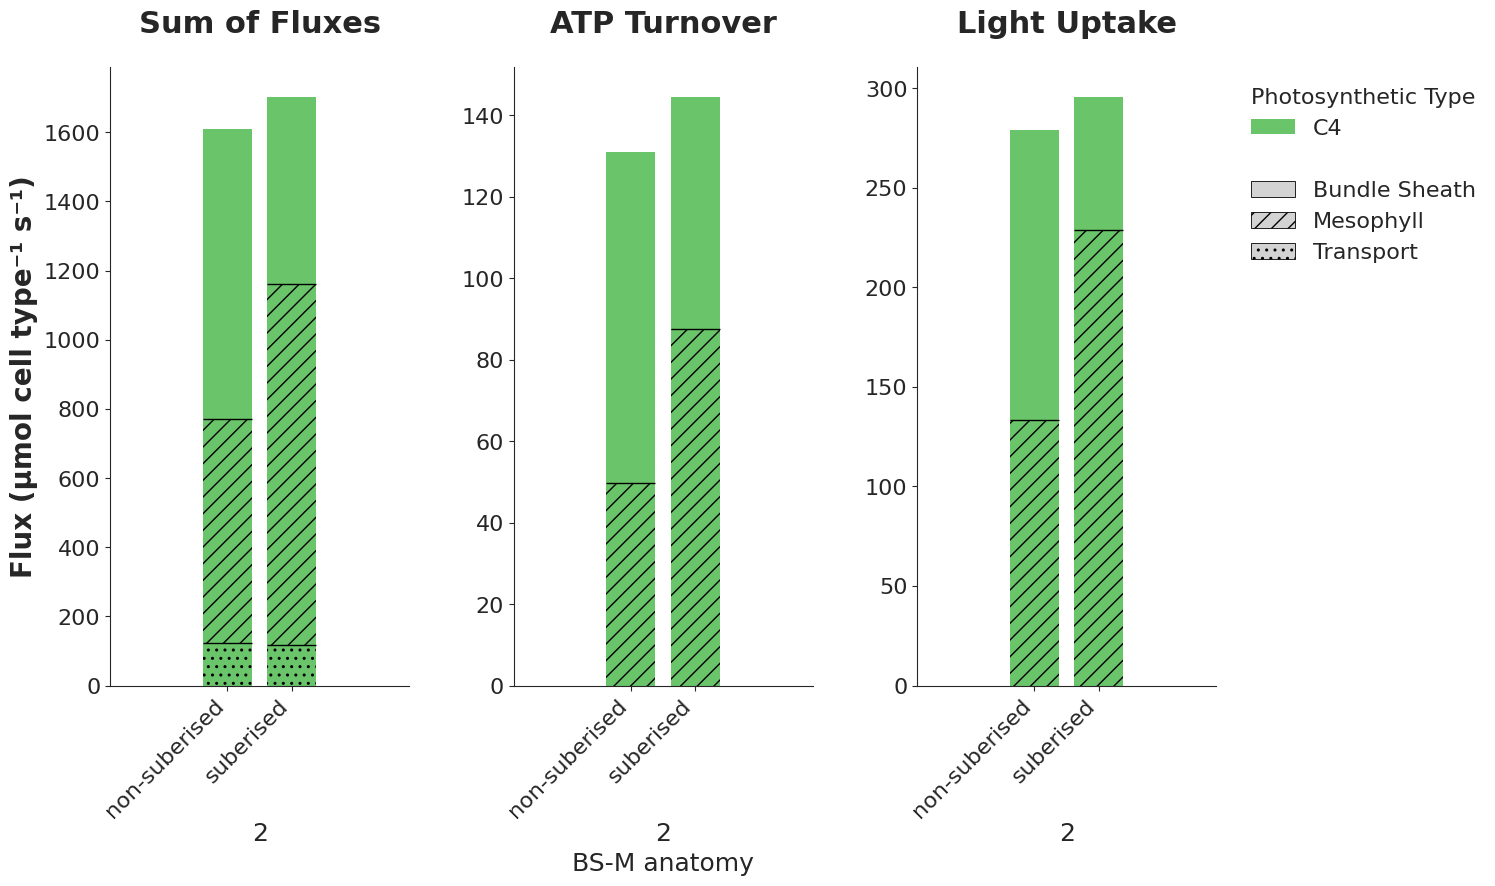

In [27]:
sub_vs_unsub_comparison_subplots( structured_C4_only_unsuberised, structured_C4_only, 1000, 75, 20, 1, 1000, volume_ratio=2)

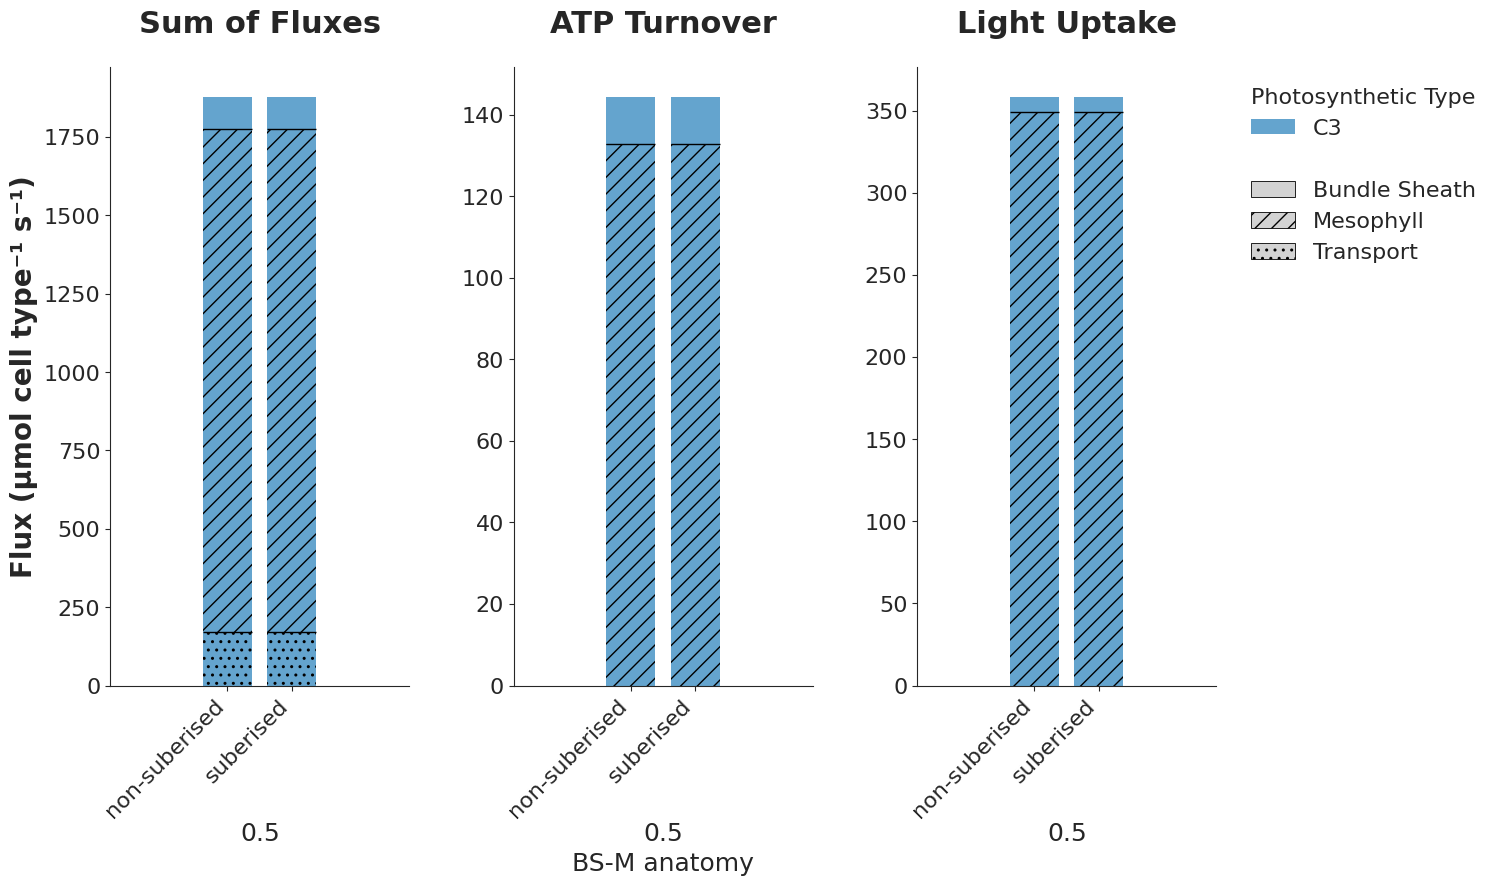

In [28]:
sub_vs_unsub_comparison_subplots( structured_C3_unsuberised, structured_C3, 1000, 75, 20, 1, 1000, volume_ratio=0.5)